# Model experiments

Central workspace for comparing architectures under a shared protocol. Architecture definitions live in `src/models/`; preparation, training, and evaluation are shared in `src/experiments.py`. Start by comparing saved models. Training is explicitly disabled by default. Character-level diagnostics belong to notebook 05.

The existing artifacts are historical single-seed experiments. Their split and class mapping are documented in the earlier notebooks, but not all have machine-readable provenance. New runs record both. The test set remains reserved for final evaluation.

In [1]:
from pathlib import Path
import sys
import json
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.models import MODELS
from src.experiments import DEFAULT_TRAINING, prepare_data, train_model, compare_models

## 1. Common data and training settings

In [2]:
training_settings = DEFAULT_TRAINING.copy()
frames, unique_char = prepare_data(seed=training_settings["seed"])
df_train = frames["train"]
df_valid = frames["validation"]
df_test = frames["test"]
BATCH_SIZE = training_settings["batch_size"]
SEED = training_settings["seed"]

display(pd.DataFrame([
    {"Split": name, "Images": len(df), "Writers": df.writer_id.nunique()}
    for name, df in frames.items()
]).set_index("Split"))

,Images,Writers
Split,,
train,47375,987
validation,10128,211
test,10223,213


## 2. Available architectures

To add an architecture, create a script with `NAME`, `ARTIFACT`, `CONFIG`, and `build_model`, then register it in `src/models/__init__.py`. Keep the training protocol common when comparing architectures.

In [3]:
display(pd.DataFrame([
    {"Key": key, "Name": definition.NAME, **definition.CONFIG}
    for key, definition in MODELS.items()
]).set_index("Key"))

,Name,filters,kernel_size,dense_units
Key,,,,
baseline,Dense 128 (baseline),"[32, 64]",3,128
dense64,Dense 64,"[32, 64]",3,64


## 3. Optional training of one selected model

Choose a model key and a unique run name. Set `RUN_TRAINING = True` only when you want to launch a new experiment. Existing artifacts are never overwritten. Each run saves the model, history, classes, architecture and training settings, and validation fingerprint.

The common runner builds a fresh training dataset and does not iterate it for a preliminary prediction. Historical notebooks consumed one shuffled batch before training, so new runs may not reproduce their exact batch order. Compare new architectures under the common runner and use multiple seeds for stronger conclusions.

In [4]:
MODEL_KEY = "dense64"
RUN_NAME = "dense64_seed12_v2"
RUN_TRAINING = False

if RUN_TRAINING:
    model, history = train_model(
        MODEL_KEY, frames, unique_char,
        run_name=RUN_NAME, settings=training_settings,
    )
else:
    print("Training disabled. Saved models can be compared below.")

Training disabled. Saved models can be compared below.


## 4. Global validation comparison

Select saved artifacts explicitly. Primary measures are validation accuracy and loss. Parameter count describes model size; character-specific confusions are diagnostics, not selection criteria. Models are evaluated after loading their saved weights. New-run provenance is checked; missing historical provenance is shown in the table.

To compare a new run, add its saved `.keras` path to `artifacts`. A model file must be available locally; these notebooks do not train missing models automatically.

In [5]:
artifacts = {
    "Dense 128 (historical baseline)": project_root / "models" / "katakana_baseline.keras",
    "Dense 64 (historical)": project_root / "models" / "katakana_dense64.keras",
}

comparison = compare_models(artifacts, df_valid, unique_char, batch_size=BATCH_SIZE)
display(comparison.style.format({
    "Parameters": "{:,.0f}",
    "Validation accuracy": "{:.2%}",
    "Validation loss": "{:.4f}",
}))
reports_dir = project_root / "reports"
reports_dir.mkdir(exist_ok=True)
comparison.to_csv(reports_dir / "model_comparison.csv")

,Parameters,Validation accuracy,Validation loss,Validation errors,Class mapping,Split provenance
Run,,,,,,
Dense 128 (historical baseline),"6,677,040",93.51%,0.2439,657,Historical assumption,Historical assumption
Dense 64 (historical),"3,347,952",93.09%,0.2517,700,Saved,Historical assumption


## 5. Learning curves for available histories

Training histories are optional for historical artifacts. Their absence is reported rather than reconstructed. The curves include epochs before EarlyStopping restored the best weights. Their last epoch is not necessarily the saved model's selected epoch.

No saved history for Dense 128 (historical baseline).


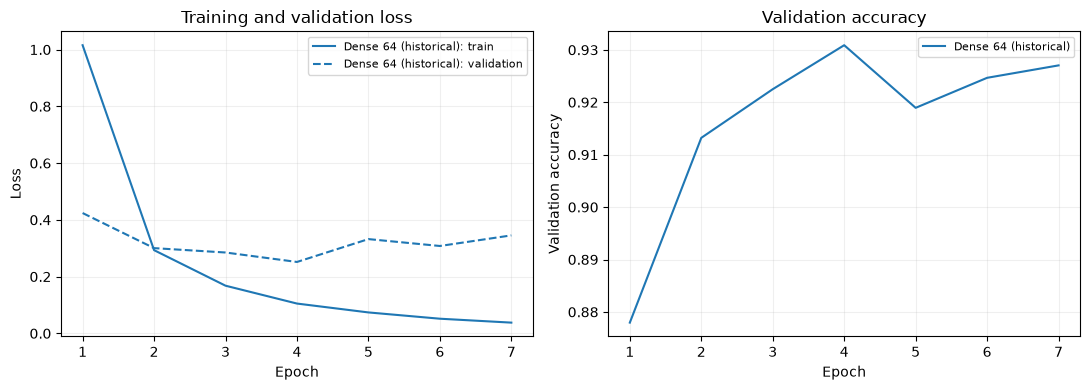

In [6]:
available_histories = {}
for name, path in artifacts.items():
    history_path = path.with_name(path.stem + "_history.json")
    if history_path.exists():
        available_histories[name] = json.loads(history_path.read_text())
    else:
        print(f"No saved history for {name}.")

if available_histories:
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    for name, values in available_histories.items():
        epochs = range(1, len(values["loss"]) + 1)
        line, = axes[0].plot(epochs, values["loss"], label=f"{name}: train")
        axes[0].plot(epochs, values["val_loss"], linestyle="--",
                     color=line.get_color(), label=f"{name}: validation")
        axes[1].plot(epochs, values["val_accuracy"], label=name)
    axes[0].set(xlabel="Epoch", ylabel="Loss", title="Training and validation loss")
    axes[1].set(xlabel="Epoch", ylabel="Validation accuracy", title="Validation accuracy")
    for ax in axes:
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
    fig.tight_layout()
    plt.show()

## 6. Interpretation and next experiment

The initial saved Dense-128 model achieves 93.51% validation accuracy and loss 0.2439; Dense-64 achieves 93.09% and loss 0.2517 with about half as many parameters. This run supports retaining Dense-128 as the accuracy reference. It does not prove that 128 is universally optimal.

Future candidates include dropout, L2 regularization, and label-preserving augmentation. Define the candidate range and keep other settings fixed before running a comparison. None is implemented in this reorganization.

Record the changed factor, global validation results, model-size trade-off, and limitations of each run. Use notebook 05 for optional error interpretation.